# 01 · Dataset Exploration & EDA
Explore the genuine Kaggle Vehicle Insurance Claim Fraud Detection CSV. Target: FraudFound_P (0 legitimate, 1 fraud). Dataset dimensions and findings are calculated at runtime; no data or results are fabricated.
Source: https://www.kaggle.com/datasets/shivamb/vehicle-claim-fraud-detection


In [1]:
%pip -q install pandas numpy matplotlib seaborn
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
try:
 from google.colab import drive, files
 drive.mount('/content/drive')
except ImportError: files=None
folder=Path('/content/drive/MyDrive/insurance_fraud_ml/data')
csvs=[p for p in folder.glob('*.csv') if p.name not in ['X_train.csv','X_test.csv','y_train.csv','y_test.csv']] if folder.exists() else []
if csvs: path=csvs[0]
elif files:
 print('Upload the original Kaggle CSV'); up=files.upload()
 if not up: raise FileNotFoundError('No CSV uploaded')
 path=Path(next(iter(up)))
else: path=Path(input('Path to original CSV: '))
if not path.exists(): raise FileNotFoundError(path)
df=pd.read_csv(path); target='FraudFound_P'
if target not in df: raise ValueError(f'Missing {target}. Found {df.columns.tolist()}')
print('Dataset:',df.shape); print('Target counts:',df[target].value_counts(dropna=False).to_dict())

Mounted at /content/drive
Upload the original Kaggle CSV


Saving fraud_oracle.csv to fraud_oracle.csv
Dataset: (15420, 33)
Target counts: {0: 14497, 1: 923}


## Inspection and data quality
Inspect actual fields, types, summary statistics, missing values and duplicates before deciding how to model.


In [2]:
display(df.head()); display(df.tail()); print('Columns:',df.columns.tolist()); display(df.dtypes.astype(str).to_frame('dtype')); display(df.describe(include='all').T); display(df.isna().sum().to_frame('missing')); print('Duplicate records:',df.duplicated().sum())

,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
15415,Nov,4,Friday,Toyota,Urban,Tuesday,Nov,5,Male,Married,...,6 years,31 to 35,No,No,External,none,no change,1 vehicle,1996,Collision
15416,Nov,5,Thursday,Pontiac,Urban,Friday,Dec,1,Male,Married,...,6 years,31 to 35,No,No,External,more than 5,no change,3 to 4,1996,Liability
15417,Nov,5,Thursday,Toyota,Rural,Friday,Dec,1,Male,Single,...,5 years,26 to 30,No,No,External,1 to 2,no change,1 vehicle,1996,Collision
15418,Dec,1,Monday,Toyota,Urban,Thursday,Dec,2,Female,Married,...,2 years,31 to 35,No,No,External,more than 5,no change,1 vehicle,1996,All Perils
15419,Dec,2,Wednesday,Toyota,Urban,Thursday,Dec,3,Male,Single,...,5 years,26 to 30,No,No,External,1 to 2,no change,1 vehicle,1996,Collision


Columns: ['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'FraudFound_P', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year', 'BasePolicy']


,dtype
Month,object
WeekOfMonth,int64
DayOfWeek,object
Make,object
AccidentArea,object
DayOfWeekClaimed,object
MonthClaimed,object
WeekOfMonthClaimed,int64
Sex,object
MaritalStatus,object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Month,15420,12,Jan,1411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WeekOfMonth,15420.0,NaN,NaN,NaN,2.788586,1.287585,1.0,2.0,3.0,4.0,5.0
DayOfWeek,15420,7,Monday,2616,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Make,15420,19,Pontiac,3837,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AccidentArea,15420,2,Urban,13822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DayOfWeekClaimed,15420,8,Monday,3757,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthClaimed,15420,13,Jan,1446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WeekOfMonthClaimed,15420.0,NaN,NaN,NaN,2.693969,1.259115,1.0,2.0,3.0,4.0,5.0
Sex,15420,2,Male,13000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaritalStatus,15420,4,Married,10625,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing
Month,0
WeekOfMonth,0
DayOfWeek,0
Make,0
AccidentArea,0
DayOfWeekClaimed,0
MonthClaimed,0
WeekOfMonthClaimed,0
Sex,0
MaritalStatus,0


Duplicate records: 0


## Class balance and distributions
Fraud datasets can be imbalanced; accuracy alone can be misleading. Interpret the observed plots and counts.


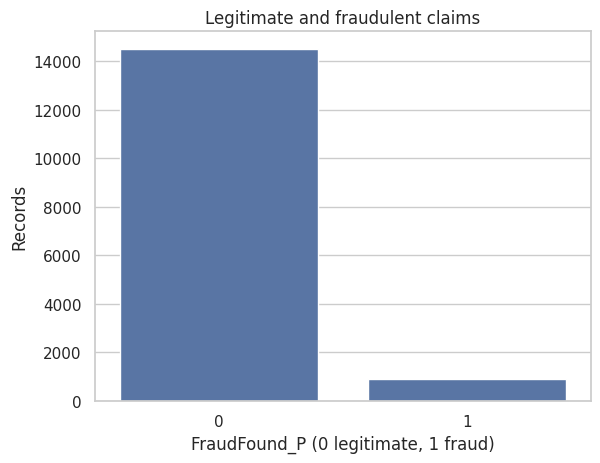

,percent
FraudFound_P,
0,94.014267
1,5.985733


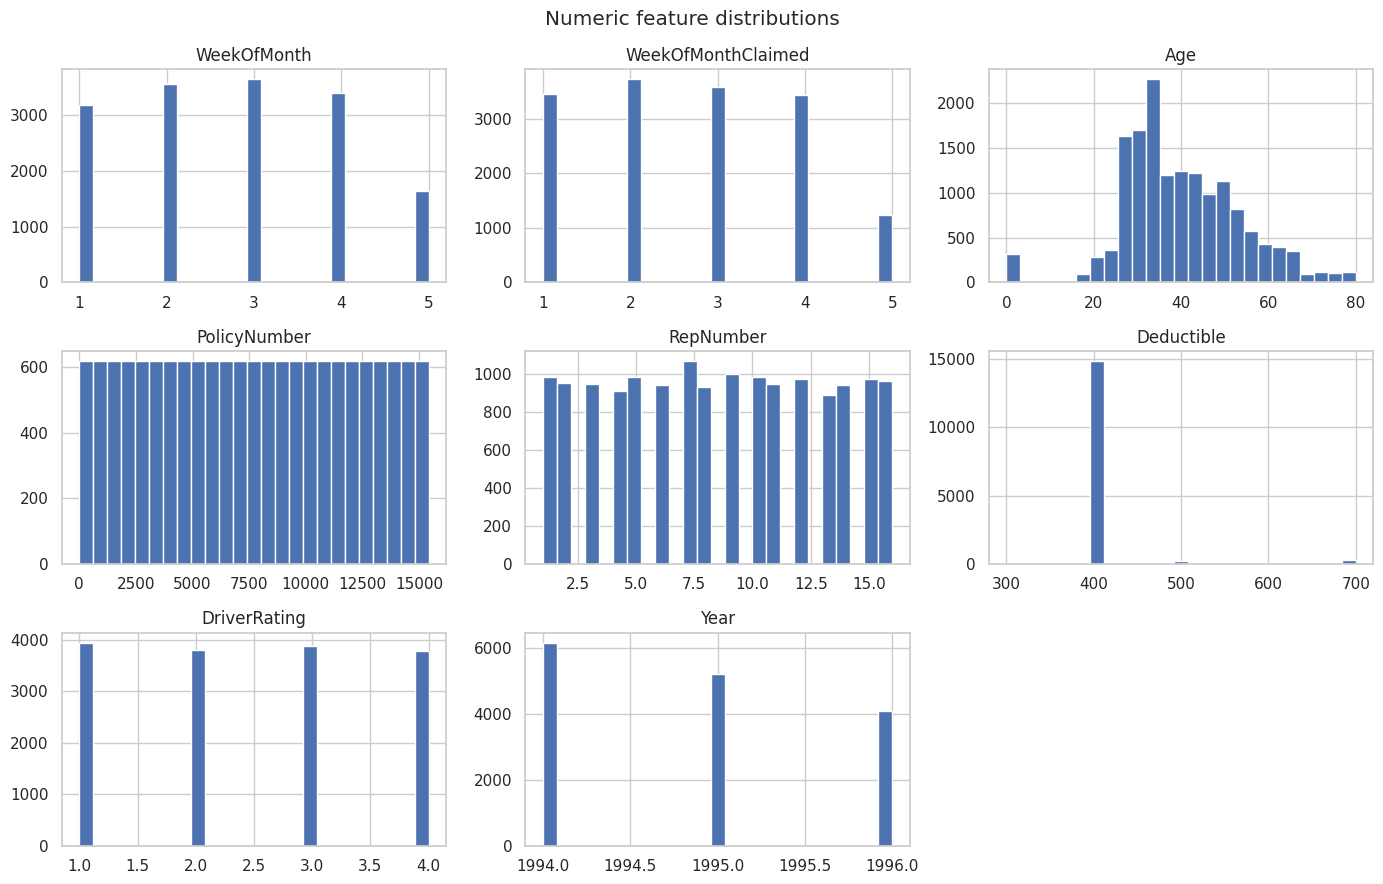

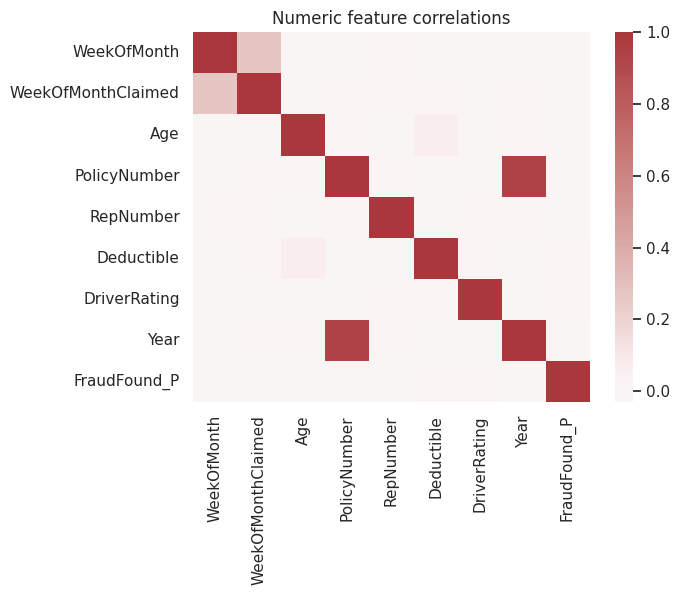

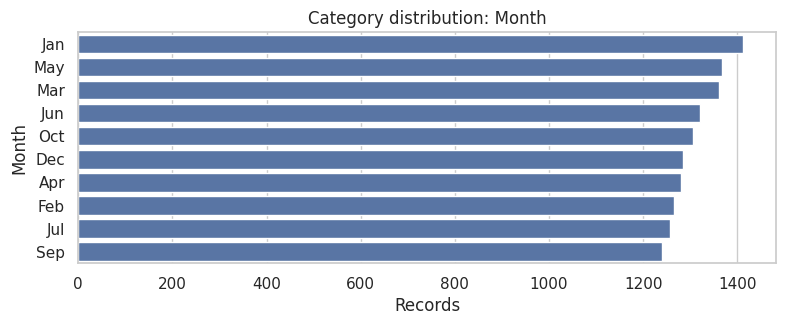

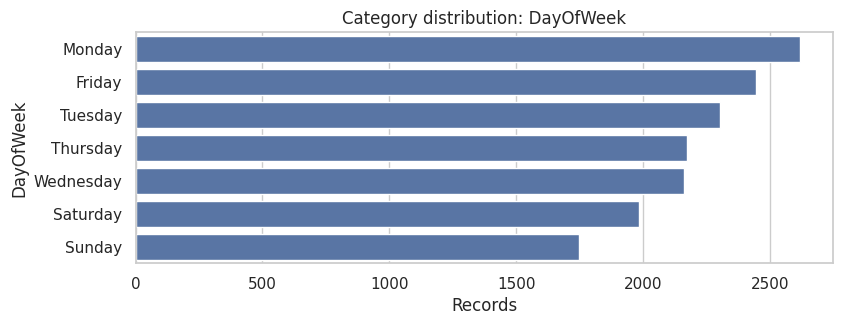

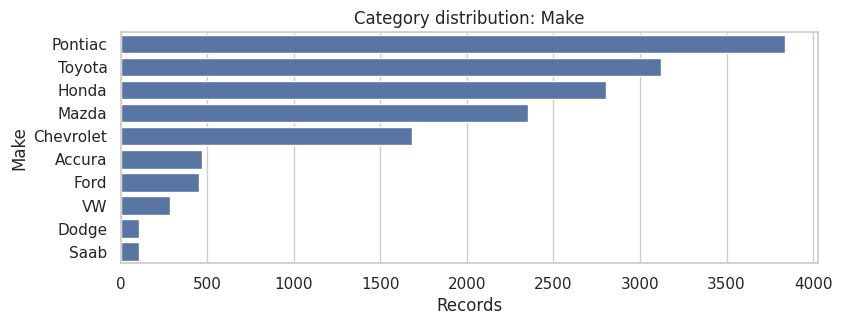

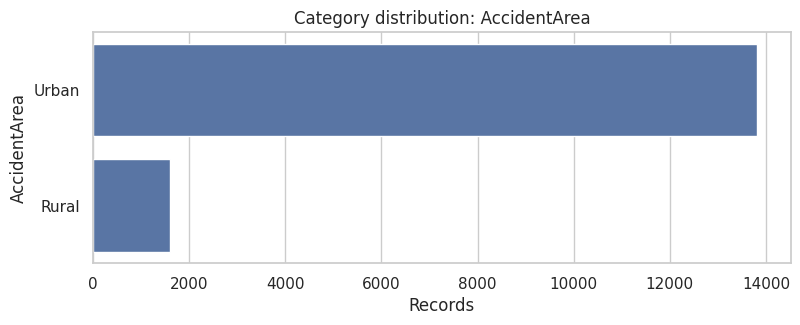

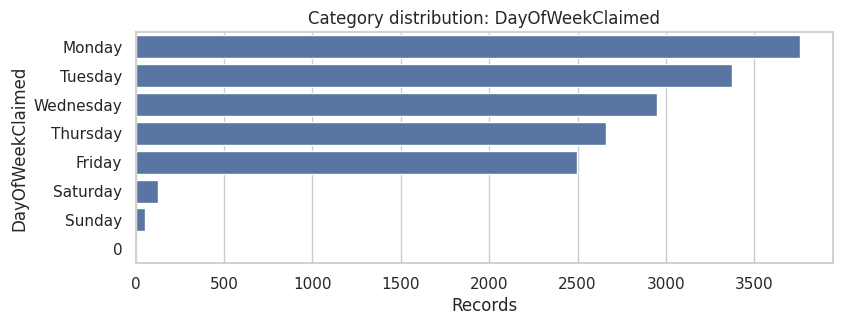

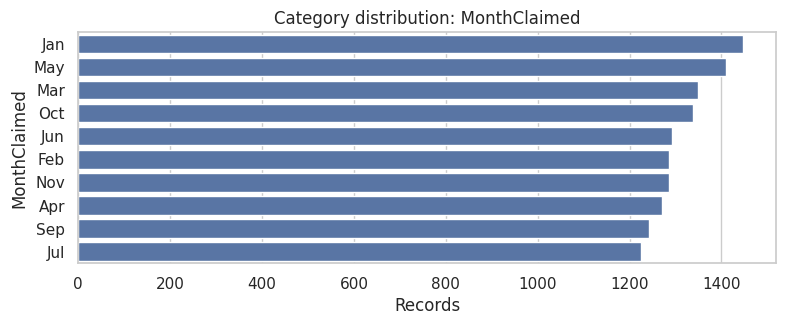

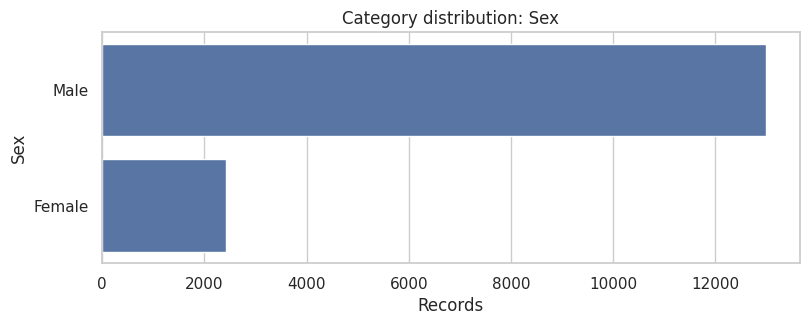

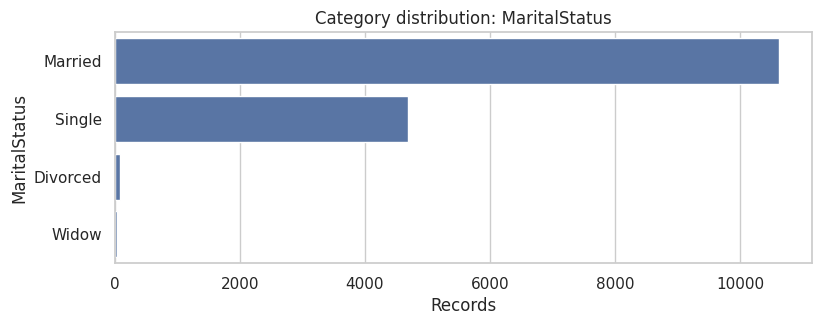

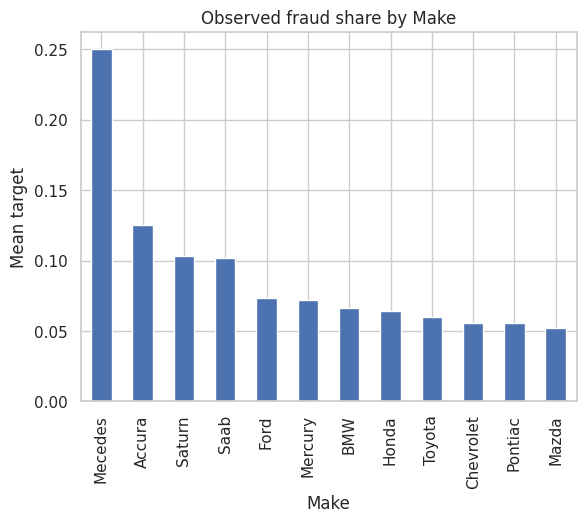

Descriptive only; small groups can be noisy.


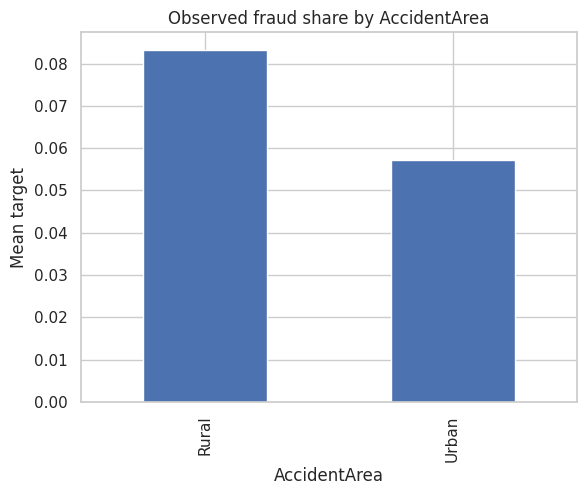

Descriptive only; small groups can be noisy.


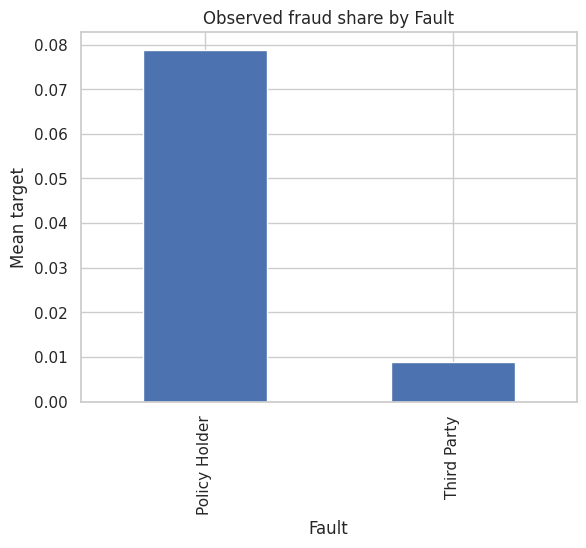

Descriptive only; small groups can be noisy.


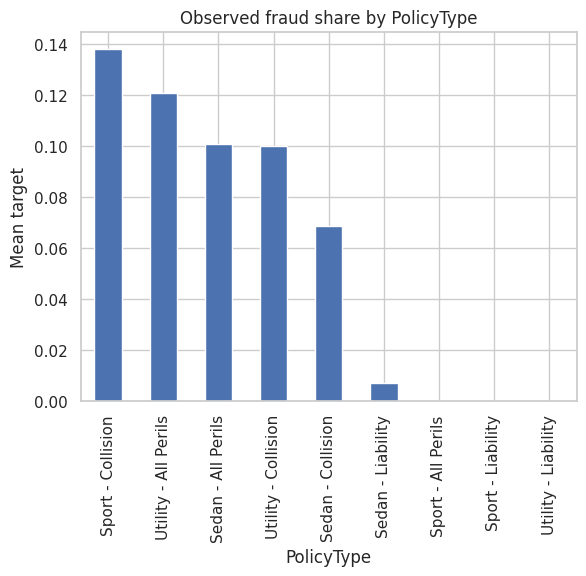

Descriptive only; small groups can be noisy.


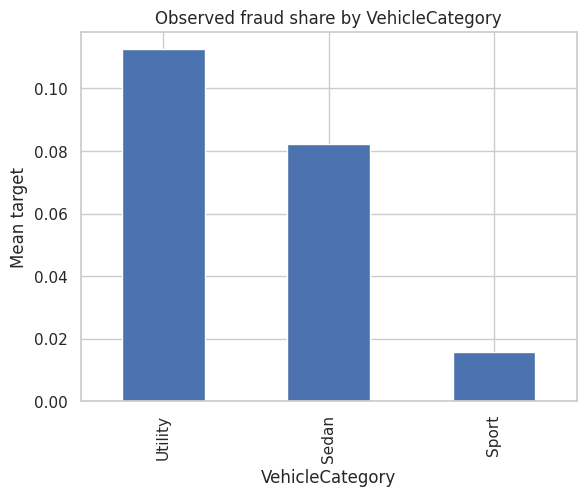

Descriptive only; small groups can be noisy.


In [3]:
sns.set_theme(style='whitegrid'); ax=sns.countplot(data=df,x=target); ax.set(title='Legitimate and fraudulent claims',xlabel='FraudFound_P (0 legitimate, 1 fraud)',ylabel='Records'); plt.show(); display((df[target].value_counts(normalize=True)*100).rename('percent').to_frame())
num=df.select_dtypes(include='number').columns.drop(target,errors='ignore').tolist()[:12]
if num: df[num].hist(figsize=(14,9),bins=25); plt.suptitle('Numeric feature distributions'); plt.tight_layout(); plt.show()
if len(num)>1: sns.heatmap(df[num+[target]].corr(numeric_only=True),cmap='vlag',center=0); plt.title('Numeric feature correlations'); plt.show()
cat=df.select_dtypes(exclude='number').columns.tolist()
for col in cat[:8]:
 vals=df[col].astype('string').fillna('Missing'); top=vals.value_counts().head(10).index
 plt.figure(figsize=(9,3)); sns.countplot(y=vals,order=top); plt.title('Category distribution: '+col); plt.xlabel('Records'); plt.ylabel(col); plt.show()
for col in [c for c in ['Make','AccidentArea','Fault','PolicyType','VehicleCategory','PoliceReportFiled','BasePolicy'] if c in df][:5]:
 d=df.assign(_y=pd.to_numeric(df[target],errors='coerce')).groupby(col,dropna=False)['_y'].mean().sort_values(ascending=False).head(12); d.plot(kind='bar',title='Observed fraud share by '+col); plt.ylabel('Mean target'); plt.show(); print('Descriptive only; small groups can be noisy.')

Interpretation: use the displayed outputs to report the real row count, class proportions, missingness, duplicates and patterns. Correlation and category rates are descriptive, not causal.